# 03 - (2,4) autoencoder: learning a 16-point constellation
**Objective.** Map 4 bits to **one complex symbol** (two real numbers: I and Q), power-normalised to E|x|^2 = 1, and compare the learned constellation with Gray 16-QAM (Task 1 modem) over AWGN.

**SNR.** One symbol carries 4 bits: Es/N0 = 4 Eb/N0 (+6.02 dB); complex noise N0 = 1/(Es/N0). 16-QAM uses nearest-neighbour (ML) detection and Gray labelling. The AE decoder outputs one of 16 messages; message-bit labels are plain binary (no Gray), which matters for BER but not for the symbol error rate (SER).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent.parent if Path.cwd().parent.name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from task2_autoencoder import experiments as ex, baselines as bl
from task2_autoencoder.autoencoder import load_model
pd.set_option("display.width", 160)
print("results ->", ex.RES, "| models ->", ex.MODELS)

results -> /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1/results/exercise1_task2 | models -> /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1/models/autoencoder


## 1. Train (Eb/N0 random in 4-12 dB)

In [2]:
model, hist = ex.train_model("ae24_awgn")
print("config:", ex.CFG["ae24_awgn"])
h = pd.DataFrame(hist, columns=["step", "loss"]); display(h.iloc[[0, len(h)//2, -1]])
cb = model.codebook().detach().numpy(); c = cb[:, 0] + 1j * cb[:, 1]
print("average |x|^2 =", round(float(np.mean(abs(c)**2)), 4))

config: {'n_real': 2, 'rx_extra': 0, 'channel': 'awgn', 'rate': 4.0, 'power': 0.5, 'ebn0': (4.0, 12.0), 'steps': 6000, 'batch': 1024, 'lr': 0.003}


,step,loss
0,0,2.779984
15,3000,0.065026
30,5999,0.114238


average |x|^2 = 1.0


## 2. Constellations

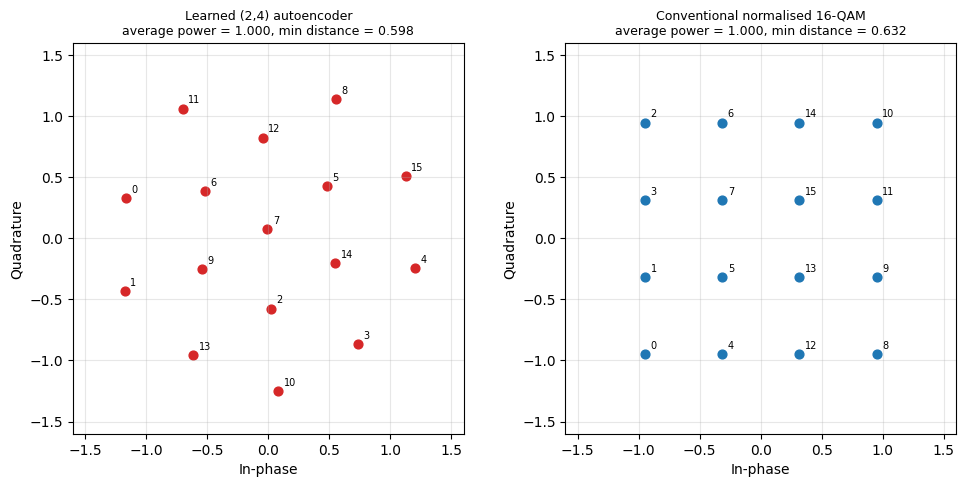

In [3]:
ex.plot_constellations(model, ex.FIG / "ae24_constellations.png"); plt.show()
pd.DataFrame({"message": range(16), "I": c.real, "Q": c.imag}).to_csv(ex.TAB / "ae24_learned_constellation.csv", index=False)

## 3. BER and SER versus Eb/N0 (2 million symbols per point)

ber                   ser          
method  autoencoder     qam16 autoencoder     qam16
ebn0_db                                            
0.0        0.253621  0.140963    0.459058  0.479300
1.0        0.218121  0.119016    0.395480  0.417338
2.0        0.181572  0.097850    0.329812  0.352425
3.0        0.144979  0.077512    0.264157  0.285926
4.0        0.109266  0.058674    0.199820  0.220862
5.0        0.077423  0.041890    0.142200  0.160537
6.0        0.050660  0.027847    0.093462  0.108306
7.0        0.029949  0.016975    0.055674  0.066726
8.0        0.015746  0.009275    0.029490  0.036758
9.0        0.007129  0.004387    0.013422  0.017466
10.0       0.002707  0.001771    0.005200  0.007070
11.0       0.000816  0.000555    0.001588  0.002218
12.0       0.000197  0.000136    0.000386  0.000542
13.0       0.000034  0.000028    0.000074  0.000114

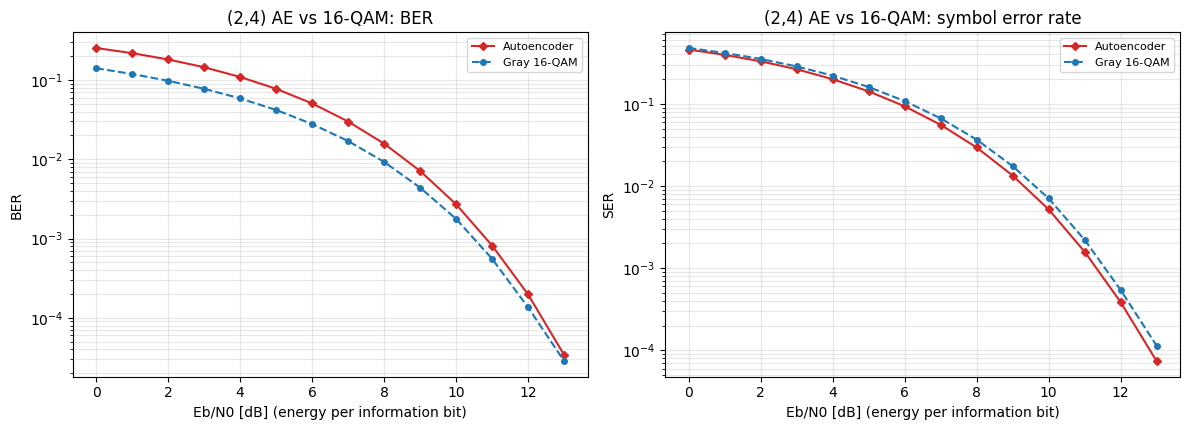

In [4]:
grid = np.arange(0, 14, 1.0)
d24 = ex.eval_24(model, grid, 2_000_000)
d24.to_csv(ex.TAB / "ae24_vs_16qam_results.csv", index=False)
display(d24.pivot(index="ebn0_db", columns="method", values=["ber", "ser"]).round(6))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
ex.plot_curves(d24, "ber", "(2,4) AE vs 16-QAM: BER", ax=axs[0], methods=["autoencoder", "qam16"])
ex.plot_curves(d24, "ser", "(2,4) AE vs 16-QAM: symbol error rate", ylabel="SER", ax=axs[1], methods=["autoencoder", "qam16"])
fig.tight_layout(); fig.savefig(ex.FIG / "ae24_vs_16qam_ber_ser.png", dpi=150); plt.show()

## 4. Explanation

In [5]:
from task1_conventional.modulation import get_modem
q = np.asarray(get_modem("16QAM").constellation()[0]).ravel()
dmin = lambda p: min(abs(a - b) for i, a in enumerate(p) for b in p[i+1:])
print(f"min distance  AE: {dmin(c):.3f}   16-QAM: {dmin(q):.3f}  (both at average power 1)")
print("peak |x|^2    AE: %.2f   16-QAM: %.2f" % ((abs(c)**2).max(), (abs(q)**2).max()))

min distance  AE: 0.598   16-QAM: 0.632  (both at average power 1)
peak |x|^2    AE: 1.62   16-QAM: 1.80


* **Learning.** The encoder only receives gradients through the noisy channel: points that are close are confused by the decoder and increase the cross-entropy, so training pushes them apart while the power constraint stops them from spreading out indefinitely. The result (see the figure) is an irregular packing: one point near the origin and the other 15 spread around it in a roughly circular/hexagonal pattern, instead of a square grid.
* **Differences from 16-QAM.** The AE has no square structure. Its minimum distance is actually slightly smaller than 16-QAM's (printed above, 0.60 vs 0.63 at equal average power), but its symbol error rate is lower: it needs about 0.3 dB less Eb/N0 than 16-QAM for SER = 1e-2 and about 0.2 dB less for SER = 1e-3 (interpolated from the table), presumably because fewer points have many close neighbours (the corner points of 16-QAM waste energy). 16-QAM has an explicit Gray labelling that makes neighbouring points differ in one bit, so its BER is about SER/4; the AE was trained on message-level cross-entropy and its bit labelling is arbitrary, so its **BER is worse than 16-QAM even though its SER is better**. Training with a bit-wise loss or a Gray-aware labelling would be needed to close this gap; we did not do it to keep the model simple.
* Every plotted point has at least 273 bit errors (2 million symbols per point), so the curves are statistically reasonable over 0-13 dB. For BER the AE is worse: about 0.7 dB more Eb/N0 for BER = 1e-2 and 0.3 dB for 1e-3.